In [1]:
# Assignment 5: Agglomerative Hierarchical Clustering Algorithm
# Aim: Implement Agglomerative Hierarchical Clustering on the Iris dataset, evaluate linkage criteria, and plot a dendrogram

Matplotlib is building the font cache; this may take a moment.


Linkage   Cophenetic corr   Silhouette(k=3)   ARI vs species  
single    0.8300            0.5046            0.5584          
complete  0.7515            0.4496            0.5726          
average   0.8544            0.4803            0.5621          
ward      0.8226            0.4467            0.6153          

Cluster sizes: [71 49 30]
Cross-tab (rows = true species, cols = cluster):
cluster   0   1   2
species            
0         0  49   1
1        23   0  27
2        48   0   2


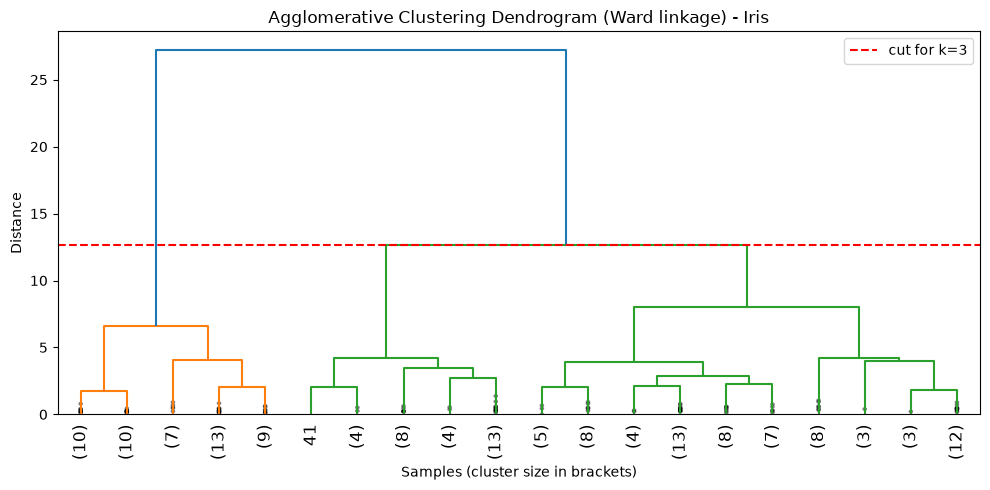


Dendrogram saved as dendrogram.png


In [3]:
# Install required libraries


import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster, cophenet
from scipy.spatial.distance import pdist
from sklearn.cluster import AgglomerativeClustering
from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score, adjusted_rand_score

# Load dataset
iris = load_iris()
X = StandardScaler().fit_transform(iris.data)
y = iris.target

# 1. Compare Linkage Criteria
print(f"{'Linkage':<10}{'Cophenetic corr':<18}{'Silhouette(k=3)':<18}{'ARI vs species':<16}")
for method in ['single', 'complete', 'average', 'ward']:
    Z = linkage(X, method=method)
    c, _ = cophenet(Z, pdist(X))
    labels = fcluster(Z, t=3, criterion='maxclust')
    print(f"{method:<10}{c:<18.4f}{silhouette_score(X, labels):<18.4f}{adjusted_rand_score(y, labels):<16.4f}")

# 2. Final Model (Ward Linkage, 3 clusters)
model = AgglomerativeClustering(n_clusters=3, linkage='ward')
labels = model.fit_predict(X)

print("\nCluster sizes:", np.bincount(labels))
print("Cross-tab (rows = true species, cols = cluster):")
print(pd.crosstab(pd.Series(y, name='species'), pd.Series(labels, name='cluster')))

# 3. Plot Dendrogram
Z = linkage(X, method='ward')
plt.figure(figsize=(10, 5))
dendrogram(Z, truncate_mode='lastp', p=20, leaf_rotation=90, show_contracted=True)
plt.axhline(y=Z[-2, 2] - 0.01, color='r', linestyle='--', label='cut for k=3')
plt.title('Agglomerative Clustering Dendrogram (Ward linkage) - Iris')
plt.xlabel('Samples (cluster size in brackets)')
plt.ylabel('Distance')
plt.legend()
plt.tight_layout()
plt.savefig('dendrogram.png', dpi=150)
plt.show()

print("\nDendrogram saved as dendrogram.png")